# Projekt: Stroke Prediction
**Aufgabe: binary classification: predict if someone is going to have a stroke or not**

**Gruppe: Adam, Farouk**

## Gliederung:

1. Datensatz und Module/Werkzeuge importieren
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Pipeline
    - weiteres Data Preprocessing (Scaling, Missing Value Imputing, Encoding)
    - Modelle anlegen
5. Pipeline & Data Preprocessing Tests
6. Baseline Modell: Logistic Regression
    - Evaluation, Performance-Metriken Schwellenwertanalyse (Threshold)
    - Ergebnis, Entscheidung und Begründung der Thresholdauswahl
    - Overfitting prüfen
7. Vergleichsmodell: Random Forest
    - Metriken und Evaluation
    - Ergebnis
8. Schlussfolgerung
    - Finales Modell: Logistic Regression (Threshold = 0.4)
9. Cross Validation
    - Ergebnis 

# 1. Datensatz und Module/Werkzeuge importieren

In [48]:
#Modul, um mit tabellarischen Daten zu arbeiten und sie zu analysieren (bzw. Dataframes zu bearbeiten):
import pandas as pd

#Modul/Werkzeug für schnelle und effiziente numerische Berechnungen.
import numpy as np

#Ermöglicht die schnelle und einfache Erstellung von 2D-/3D-Diagrammen und Visualisierungen.
import matplotlib.pyplot as plt

#Hilft dabei, statistische Daten zu visualisieren und informative Diagramme zu erstellen.
import seaborn as sns

#Zusätzlich zu den bisher gelisteten Imports wurden im Projektverlauf natürlich auch weitere Module verwendet.

In [49]:
#Einlesen der CSV-Datei "stroke.csv" bzw. unserem Datensatzes:
#Wir speichern diesen als Pandas-DataFrame "df" ein um ihn später zu verwenden:
df = pd.read_csv("stroke.csv")

# 2. Exploratory Data Analysis (EDA)
**Überblick über den Datensatz bekommen:**

In [50]:
#Die ersten fünf Zeilen des DataFrames (df) anzeigen, um einen ersten Eindruck von den Daten zu bekommen:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [51]:
#Eine Übersicht über die Struktur bzw. alle Spalten des DataFrames:
#(Spaltennamen, Datentypen, Anzahl der Einträge pro Spalte bzw. insgesamt, Speicherverbrauch)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [52]:
#Ausgeben der wichtigsten statistischen Daten zu den einzelnen Features
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


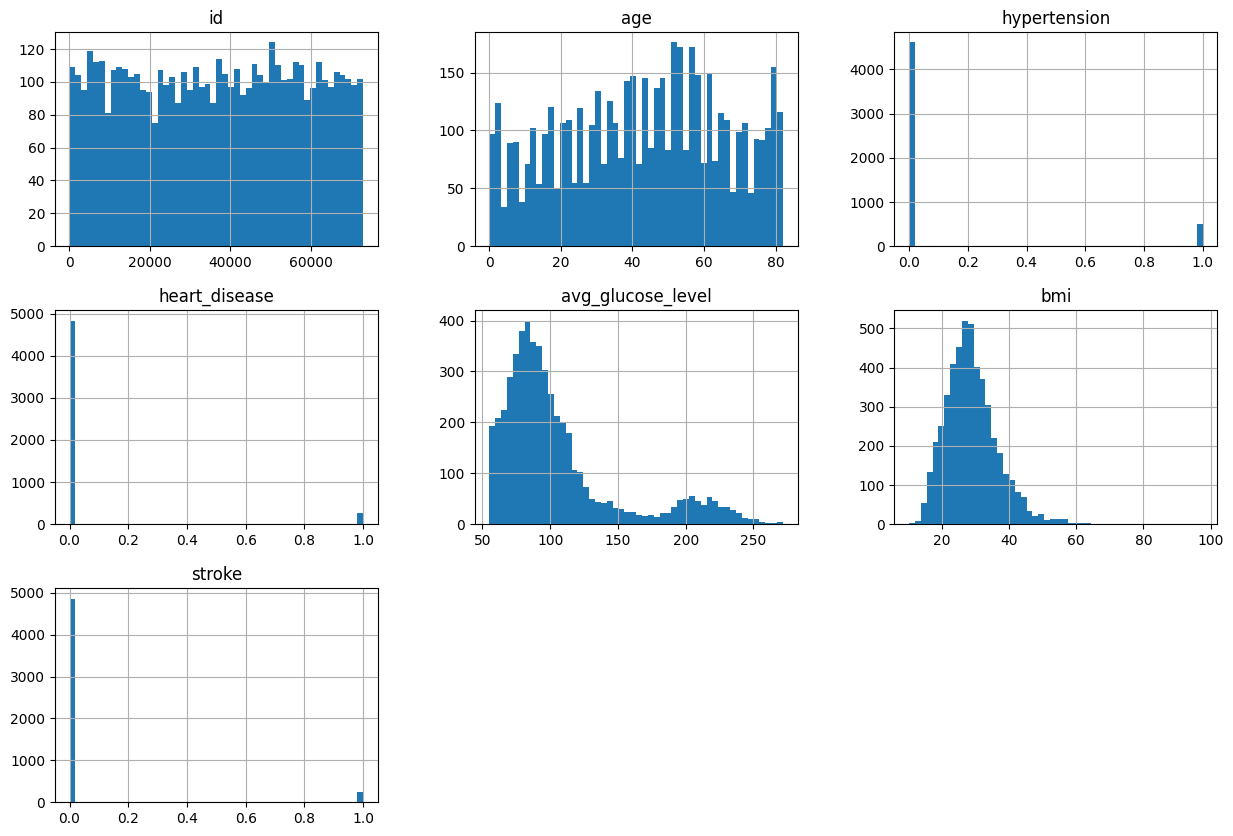

In [53]:
#Generieren und Anzeige von Histogrammen der Features 
df.hist(bins=50, figsize=(15,10))
plt.show()

In [54]:
#Korrelationsmatrix
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
id,1.000000,0.003538,0.003550,-0.001296,0.001092,0.003084,0.006388
age,0.003538,1.000000,0.276398,0.263796,0.238171,0.333398,0.245257
hypertension,0.003550,0.276398,1.000000,0.108306,0.174474,0.167811,0.127904
heart_disease,-0.001296,0.263796,0.108306,1.000000,0.161857,0.041357,0.134914
avg_glucose_level,0.001092,0.238171,0.174474,0.161857,1.000000,0.175502,0.131945
bmi,0.003084,0.333398,0.167811,0.041357,0.175502,1.000000,0.042374
stroke,0.006388,0.245257,0.127904,0.134914,0.131945,0.042374,1.000000


In [55]:
#Explizit die Stroke Spalte der Korrelationsmatrix ausgeben
corr_matrix["stroke"].sort_values(ascending=False)

stroke               1.000000
age                  0.245257
heart_disease        0.134914
avg_glucose_level    0.131945
hypertension         0.127904
bmi                  0.042374
id                   0.006388
Name: stroke, dtype: float64

In [56]:
#Berechnung der Anzahl von fehlenden Werte (NaN) in jeder Spalte, um festzustellen, wo Datenbereinigung erforderlich ist:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [57]:
#Anzeigen der Zeilen, die mindestens einen fehlenden Wert (NaN) enthalten:
df[df.isnull().any(axis=1)]

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,61843,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5039,42007,Male,41.0,0,0,No,Private,Rural,70.15,NaN,formerly smoked,0
5048,28788,Male,40.0,0,0,Yes,Private,Urban,191.15,NaN,smokes,0
5093,32235,Female,45.0,1,0,Yes,Govt_job,Rural,95.02,NaN,smokes,0
5099,7293,Male,40.0,0,0,Yes,Private,Rural,83.94,NaN,smokes,0


In [58]:
#Feature Body-Mass-Index (bmi) genauer anschauen
df["bmi"].describe()

count    4909.000000
mean       28.893237
std         7.854067
min        10.300000
25%        23.500000
50%        28.100000
75%        33.100000
max        97.600000
Name: bmi, dtype: float64

<Axes: >

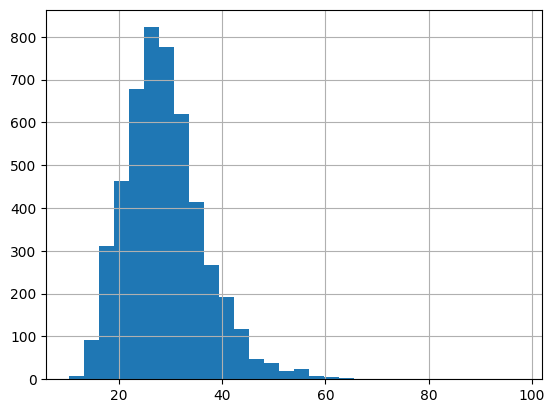

In [59]:
#Visualisierung (Histogramm) von BMI
df["bmi"].hist(bins=30)

In [60]:
#Überprüfung der Anzahl der doppelten Einträge (Duplikate) im Datensatz:
df.duplicated().sum()

np.int64(0)

In [61]:
#alle kat. Features ausgeben
df.select_dtypes(include="object").columns

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')

In [62]:
#ein bisschen genauer alles ausgeben (Features und deren Typarten)
df.dtypes

id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

In [63]:
df["gender"].unique() #One-Hot-Encoder

array(['Male', 'Female', 'Other'], dtype=object)

In [64]:
df["ever_married"].unique() #Manuell binär Encoden zu Yes=1, No=0

array(['Yes', 'No'], dtype=object)

In [65]:
df["work_type"].unique() #One-Hot-Encoder

array(['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked'],
      dtype=object)

In [66]:
df["Residence_type"].unique() #Manuell binär Encoden oder One-Hot-Encoder

array(['Urban', 'Rural'], dtype=object)

In [67]:
df["smoking_status"].unique() #nicht ordinal encodbar durch kategorielle Ausprägung: "Unknown", deswegen One-Hot-Encoder

array(['formerly smoked', 'never smoked', 'smokes', 'Unknown'],
      dtype=object)

In [68]:
#Wie viele Stroke Fälle bzw. Instanzen mit Stroke=1 & Stroke=0 haben wir?
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

# 3. Data Preprocessing
**Veränderungen im Datensatz**

In [69]:
#Feature "id" entfernen, da es für unsere Modelle keine Hilfe ist und nur mögliches unnötiges Bias verursachen würde
df = df.drop(columns=["id"])

In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
#Encoden von der Spalten: ever_married und Residence_type:
#Darf vor dem Train-Test-Split gemacht werden, da bei binärem, festem Mapping keine Gefahr von Leakage besteht
df["ever_married"] = df["ever_married"].map({"Yes": 1, "No": 0})
df["Residence_type"] = df["Residence_type"].map({"Urban": 1, "Rural": 0})
#hypertension, heart_disease schon 0/1

In [72]:
#Train-Test-Split:
from sklearn.model_selection import train_test_split

X = df.drop("stroke", axis=1)
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y, #damit stroke=1 sich gut verteilt im Split
    random_state=42
)

# 4. Pipeline
## inkl. weiterem Data Preprocessing & Modelle anlegen

In [73]:
#Pipeline erstellen
#Importieren von genutzen Modulen (Scaling, Encoding, etc.)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

#Erstellen der Kategorieren von Spalten für spätere Nutzung und Veränderungen
cat_cols = ["gender", "work_type", "smoking_status"]
num_cols = ["age", "avg_glucose_level", "bmi"]
bin_cols = ["ever_married", "Residence_type", "hypertension", "heart_disease"]

#Pipeline
preprocess = ColumnTransformer(
    transformers=[
        #Numerische Features scaling & missing value imputing durch Median 
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

#Scaling von wichtigen Features: age, avg_glucose_level, bmi
#Wieso genau die 3?: Die 3 Features sind die einzigen mit unterschiedlichen Wertebereichen.
#-> Durch Standardisierung wird verhindert, dass Merkmale mit größeren Zahlenbereichen das Modell unverhältnismäßig stark beeinflussen.

        #Enkodierung durch OHE der restlichen kat. Features
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),

        #binäre Features (keine Veränderung)
        ("bin", "passthrough", bin_cols),
    ]
)

#Modell anlegen für binäre Klassifikation:
#Welches Modell? (Wir haben: tabellarische Daten, gemischte Features kat. & num., starke Klassenimbalance, medizinische Daten/Kontext)

#Überlegungen:
#KNN? -> SCHLECHT => zu viele Dimensionen (-> Curse of Dimensionality), empfindlich gegenüber Scaling, Klassenimbalance schlecht bei KNN
#Naive Bayes? -> MITTELMÄßIG => Features sind nicht unabhängig, OHE + numerische Daten = unpassend, schwer zu rechtfertigen da medizinisches Problem
#Logistic Regression? -> GUT => liefert Wahrscheinlichkeiten, gut interpretierbar, gute Stabilität trotz wenig positiver Fälle, ...
#Random Forest? -> GUT => lernt nichtlineare Zusammenhänge, robust, wenig Feature-Engineering nötig, Imbalance weniger problematisch, aber: Interpretierbarkeit schlechter 

#Logistic Regression (Baseline)
pipe = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

In [74]:
#Modell(e) trainieren (nur Trainingsdaten - noch keine Evaluierung) & alle Vorverarbeitungsschritte ausführen
pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'avg_glucose_level',
                                                   'bmi']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'work_type',
                                                   'smoking_status']),
                                                 ('bin', 'passthrough',
                                                  ['ever_married',
                                                   'Residence_type',
                                                   'hypertension',
                                                   'heart_disease'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [75]:
#Soft Classification (=Wahrscheinlichkeiten)
y_proba = pipe.predict_proba(X_test)[:, 1]

# 5. Pipeline & Data Preprocessing Tests:

In [76]:
#1 Encoding Test
X_transformed = pipe.named_steps["preprocess"].transform(X_train)
print(X_train.shape, "->", X_transformed.shape)
feature_names = pipe.named_steps["preprocess"].get_feature_names_out()
feature_names[:20]
#X_transformed > X_train & neue Spalten(-namen)? => Test erfolgreich!

(4088, 10) -> (4088, 16)


array(['num__age', 'num__avg_glucose_level', 'num__bmi',
       'cat__gender_Male', 'cat__gender_Other',
       'cat__work_type_Never_worked', 'cat__work_type_Private',
       'cat__work_type_Self-employed', 'cat__work_type_children',
       'cat__smoking_status_formerly smoked',
       'cat__smoking_status_never smoked', 'cat__smoking_status_smokes',
       'bin__ever_married', 'bin__Residence_type', 'bin__hypertension',
       'bin__heart_disease'], dtype=object)

In [77]:
#2 weiterer Encoding Test (One-Hot-Encoder)
X_transformed_df = pd.DataFrame(X_transformed, columns=feature_names)
X_transformed_df.filter(like="cat__").head()
#Spalten_werte = 1/0 => Test erfolgreich!

,cat__gender_Male,cat__gender_Other,cat__work_type_Never_worked,cat__work_type_Private,cat__work_type_Self-employed,cat__work_type_children,cat__smoking_status_formerly smoked,cat__smoking_status_never smoked,cat__smoking_status_smokes
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [78]:
#3 Imputing-Missing-Value Test
X_transformed_df.isna().sum().sum()
#Test ob fehlende Wertee des Features "bmi" (=Body-Mass-Index) noch existieren nach der Ersetzung durch den Median im Trainset:
#0 NaN-Werte? => Test erfolgreich!

np.int64(0)

In [79]:
#4 Scaling Test
X_transformed_df.filter(like="num__").describe()
#Wurde richtig skaliert? -> Mean ≈ 0 & Std ≈ 1 => Test erfolgreich!

,num__age,num__avg_glucose_level,num__bmi
count,4.088000e+03,4.088000e+03,4.088000e+03
mean,-1.564306e-17,3.702192e-16,-3.749990e-16
std,1.000122e+00,1.000122e+00,1.000122e+00
min,-1.915251e+00,-1.131326e+00,-2.393908e+00
25%,-7.680467e-01,-6.409288e-01,-6.548823e-01
50%,7.288256e-02,-3.175881e-01,-1.138522e-01
75%,7.810336e-01,1.741352e-01,5.044680e-01
max,1.710482e+00,3.655421e+00,8.851790e+00


# 6. Baseline Modell: Logistic Regression
## Evaluation, Performance-Metriken & Schwellenwertanalyse (Threshold)

In [80]:
#Schwellenwert (threshold) festlegen (Hard-Classification)
y_pred = (y_proba >= 0.4).astype(int) #Am Anfang auf 0.5 gesetzt, jetzt 0.4 (Begründung sind die Metriken und der Schlusssatz - siehe unten)

In [81]:
#ROC-AUC (Receiver Operating Characteristic & Area Under the Curve)
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_proba)
print("ROC-AUC:", roc_auc)
#Diese Metrik misst unabhängig vom Schwellenwert:
#Es misst wie gut das Modell Stroke- und Nicht-Stroke-Patienten anhand ihrer vorhergesagten Wahrscheinlichkeiten trennen kann:

#   Interpretation:
#   0.5          =   Zufall
#   0.6 - 0.7    =   schwach
#   0.7 - 0.8    =   ok
#   0.8 - 0.9    =   gut
#   > 0.9        =   sehr gut

#Ergebnis: 0.8436 = gut

ROC-AUC: 0.8436008230452675


In [82]:
#Confusion-Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

#Ausgabe:
#[[TN FP]
#[FN TP]]

Confusion Matrix:
 [[661 311]
 [  8  42]]


In [83]:
#Recall (Trefferquote der Positiven)
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)
print("Recall (Stroke=1):", recall)
#Rechnung: TP/(TP+FP)

# => Interpretation: Ergebnis bedeutet wie viel % der Patienten mit Stroke = 1 werden erkannt

Recall (Stroke=1): 0.84


In [84]:
#F1-Score (Kompromiss zwischen Precision und Recall)
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)
# [0,1] 0 = schlecht & 1 = perfekt

F1-Score: 0.20843672456575682


In [85]:
#Zusammenfassung der Metriken
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.988     0.680     0.806       972
           1      0.119     0.840     0.208        50

    accuracy                          0.688      1022
   macro avg      0.554     0.760     0.507      1022
weighted avg      0.946     0.688     0.776      1022



In [86]:
#Schwellenwerte (Thresholds) vergleichen:
from sklearn.metrics import recall_score, f1_score, confusion_matrix

def evaluate_threshold(y_true, y_proba, threshold):
    y_pred = (y_proba >= threshold).astype(int)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    return recall, f1, cm

for t in [0.6, 0.5, 0.4, 0.3]:
    recall, f1, cm = evaluate_threshold(y_test, y_proba, t)
    print(f"\nThreshold = {t}")
    print("Recall:", round(recall, 3))
    print("F1:", round(f1, 3))
    print("Confusion Matrix:\n", cm)


Threshold = 0.6
Recall: 0.78
F1: 0.281
Confusion Matrix:
 [[783 189]
 [ 11  39]]

Threshold = 0.5
Recall: 0.8
F1: 0.235
Confusion Matrix:
 [[722 250]
 [ 10  40]]

Threshold = 0.4
Recall: 0.84
F1: 0.208
Confusion Matrix:
 [[661 311]
 [  8  42]]

Threshold = 0.3
Recall: 0.84
F1: 0.174
Confusion Matrix:
 [[580 392]
 [  8  42]]


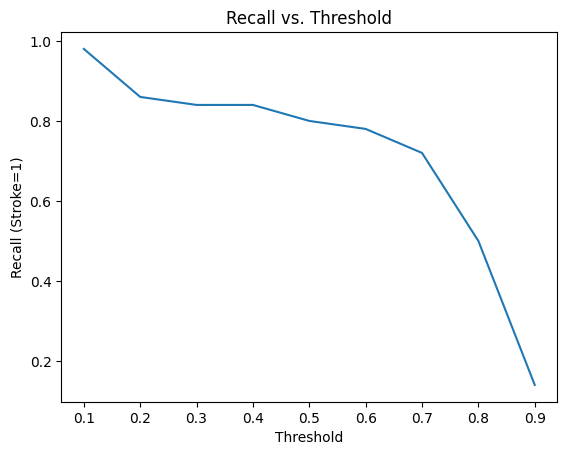

In [87]:
#Recall vs. Threshold - Plot
import numpy as np
import matplotlib.pyplot as plt

thresholds = np.linspace(0.1, 0.9, 9)
recalls = []

for t in thresholds:
    recalls.append(recall_score(y_test, (y_proba >= t).astype(int)))

plt.plot(thresholds, recalls)
plt.xlabel("Threshold")
plt.ylabel("Recall (Stroke=1)")
plt.title("Recall vs. Threshold")
plt.show()

## Ergebnis, Entscheidung und Begründung der Thresholdauswahl:
**Wir entscheiden uns für Threshold = 0.4 (heißt: Ab 40% Wahrscheinlichkeit für einen Stroke sagen wir Stroke = 1)**
**Wieso?: Von 0.5 auf 0.4 minimieren wir die FN von 10 auf 8 wodurch 2 Patienten "gerettet" werden für die Kosten von 61 FP**
**Das ist in der Medizin ein sehr guter Trade,**
**da wir lieber ein paar Patienten falsch als Stroke = 1 hervorsagen um für mehr Sicherheit sorgen**
**Bei einem Threshold von 0.3 ändert sich auch nichts mehr an den FN und die FP steigen exponetiell**
**Dadurch können wir ausschließen einen noch kleineren Threshold zu wählen**

## Overfitting prüfen

In [88]:
#Dafür verwendete Metrik: ROC-AUC Vergleich zwischen Train und Test
from sklearn.metrics import roc_auc_score

# Wahrscheinlichkeiten
y_train_proba = pipe.predict_proba(X_train)[:, 1]
y_test_proba  = pipe.predict_proba(X_test)[:, 1]

# ROC-AUC
train_auc = roc_auc_score(y_train, y_train_proba)
test_auc  = roc_auc_score(y_test,  y_test_proba)

print("Train ROC-AUC:", round(train_auc, 4))
print("Test  ROC-AUC:", round(test_auc, 4))

#   Interpretation:
#   Train ≈ Test    =>  Good Fit        (Differenz von < 0.05 erwünscht - ab 0.1 eher kritisch)
#   Train >> Test   =>  Overfitting
#   Beides niedrig  =>  Underfitting


Train ROC-AUC: 0.8469
Test  ROC-AUC: 0.8436


**Ergebnis: Differenz von 0.0033 => kein Hinweis auf Overfitting**

# 7. Vergleichsmodell: Random Forest

In [89]:
#Pipeline Erweiterung bzw. Vergleichsmodell-Einbau (Random Forest)

from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=200, #Anzahl der Entscheidungsbäume auf 200 gesetzt (200-500 = Praxisstandart) für gute Performance
        random_state=42,
        class_weight="balanced"
    ))
])

In [90]:
#RF trainieren
rf_pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'avg_glucose_level',
                                                   'bmi']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'work_type',
                                                   'smoking_status']),
                                                 ('bin', 'passthrough',
                                                  ['ever_married',
                                                   'Residence_type',
                                                   'hypertension',
                                                   'heart_disease'])])),
                ('clf',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

## Metriken & Evaluation

In [91]:
#Wahrscheinlichkeiten
rf_y_proba = rf_pipe.predict_proba(X_test)[:, 1]

#ROC-AUC
from sklearn.metrics import roc_auc_score
rf_auc = roc_auc_score(y_test, rf_y_proba)
print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.785812757201646


In [92]:
#Metriken für threshold = 0.5
from sklearn.metrics import recall_score, confusion_matrix, f1_score

rf_y_pred = (rf_y_proba >= 0.5).astype(int)

print("RF Recall:", recall_score(y_test, rf_y_pred))
print("RF F1:", f1_score(y_test, rf_y_pred))
print("RF Confusion Matrix:\n", confusion_matrix(y_test, rf_y_pred))

RF Recall: 0.0
RF F1: 0.0
RF Confusion Matrix:
 [[971   1]
 [ 50   0]]


In [93]:
#Metriken für unterschiedliche thresholds
from sklearn.metrics import recall_score, f1_score, confusion_matrix

for t in [0.5, 0.4, 0.3, 0.2, 0.1, 0.025]:
    rf_y_pred = (rf_y_proba >= t).astype(int)
    print(f"\nRF threshold={t}")
    print("Recall:", recall_score(y_test, rf_y_pred))
    print("F1:", f1_score(y_test, rf_y_pred))
    print("CM:\n", confusion_matrix(y_test, rf_y_pred))


RF threshold=0.5
Recall: 0.0
F1: 0.0
CM:
 [[971   1]
 [ 50   0]]

RF threshold=0.4
Recall: 0.04
F1: 0.06896551724137931
CM:
 [[966   6]
 [ 48   2]]

RF threshold=0.3
Recall: 0.1
F1: 0.1388888888888889
CM:
 [[955  17]
 [ 45   5]]

RF threshold=0.2
Recall: 0.2
F1: 0.18691588785046728
CM:
 [[925  47]
 [ 40  10]]

RF threshold=0.1
Recall: 0.56
F1: 0.25225225225225223
CM:
 [[828 144]
 [ 22  28]]

RF threshold=0.025
Recall: 0.82
F1: 0.18468468468468469
CM:
 [[619 353]
 [  9  41]]


## Ergebnis: 
**Random Forest hat eine deutlich schlechtere Performance trotz möglichem Tuning durch Veränderung der Anzahl von Entscheidungsbäumen sowie des Thresholds**

# 8. Schlussfolgerung - Finales Modell
## Klare Entscheidung: Finales Modell -> Logistic Regression mit einem Threshold von 0.4

# 9. Cross Validation:

In [94]:
#Cross Validation Import
from sklearn.model_selection import StratifiedKFold, cross_val_score

#StratifiedKFold ist wichtig, da Stroke = 1 im Datensatz selten vorkommt und wir immer eine gute Verteilung in den Sets haben möchten
cv = StratifiedKFold(
    n_splits=5, #5-fold Cross Validation (heißt: Daten werden in 5 Teile geteilt - 5 Durchläufe)
    shuffle=True, #Daten mischen vor dem Aufteilen
    random_state=42 #Um Folds reproduzierbar zu machen/abzuspeichern (Die Wahl der Zahl ist egal)
)


cv_scores = cross_val_score(
    pipe,          # Logistic Regression Pipeline (Random Forest ausgeschlossen)
    X, y,
    cv=cv,
    scoring="roc_auc"
)

print("ROC-AUC Cross-Validation Scores:", cv_scores) #alle 5 ROC-Auc Scores
print("Mean ROC-AUC:", cv_scores.mean()) #Durchschnitt der CV-ROC-AUC Scores
print("Std ROC-AUC:", cv_scores.std()) #Standardabweichung der Scores (Maß für die Stabilität)

ROC-AUC Cross-Validation Scores: [0.82903292 0.8250823  0.85997942 0.86430041 0.80653145]
Mean ROC-AUC: 0.8369853025904511
Std ROC-AUC: 0.02194175733776607


## Ergebnis der Cross Validation
**Mean ROC-AUC ≈ 0.837 -> praktisch identisch zu dem obigen ROC-AUC Test ohne Cross-Validation (≈0.84)**

**-> Resultat: kein Zufallsergebnis**

**Standardabweichung ≈ 0.0219 -> niedrig => stabiles Modell**

## Gesamtresultat: Die Stabilität des Modells wurde durch Cross-Validation klar bestätigt
